# Monte Carlo Simulation of Random Walks and Diffusion

## Introduction

Random walks are stochastic processes used to model random
particle motion and diffusion.

In this project, we use Monte Carlo simulations to investigate
how particles move randomly and how their mean squared
displacement (MSD) changes over time.

## Objectives

- Simulate one-dimensional random walks.
- Extend the simulation to multiple particles.
- Calculate the mean squared displacement (MSD).
- Compare numerical results with theoretical predictions.
- Estimate the diffusion coefficient.
- Explore two-dimensional random walks.

## 1. One-Dimensional Random Walk

We simulate a particle that randomly moves one step to
the left or right at each time step, with equal probability.

The position is updated according to:

$$x_{n+1} = x_n + \Delta x_n$$

where $\Delta x_n = \pm 1$.

We visualize the particle's trajectory over 1000 steps.

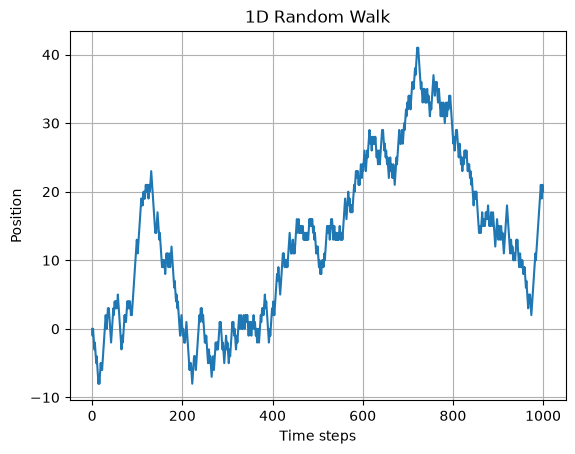

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

N = 1000
steps = np.random.choice([-1, 1], size=N)
position = np.concatenate(([0], np.cumsum(steps)))

plt.plot(position)
plt.xlabel("Time steps")
plt.ylabel("Position")
plt.title("1D Random Walk")
plt.grid(True)
plt.show()

## 2. Simulation of Multiple Particles

We extend the simulation to 1000 independent particles. All particles start at the origin and perform random walks. We visualize 20 trajectories to observe how particles
spread over time.

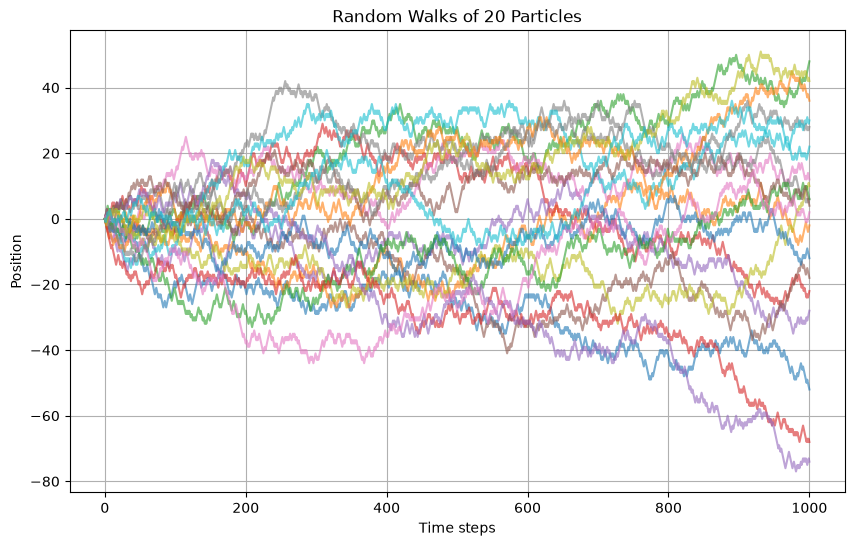

In [2]:
num_particles = 1000
num_steps = 1000

steps = np.random.choice([-1, 1], size=(num_particles, num_steps))

positions = np.cumsum(steps, axis=1)

positions = np.column_stack((np.zeros(num_particles), positions))

plt.figure(figsize=(10, 6))

for i in range(20):
    plt.plot(positions[i], alpha=0.6)

plt.xlabel("Time steps")
plt.ylabel("Position")
plt.title("Random Walks of 20 Particles")
plt.grid(True)
plt.show()

## 3. Mean Squared Displacement (MSD)

The mean squared displacement measures how far particles spread from their initial positions. For normal diffusion in one dimension:

$$\langle x^2(t)\rangle = 2Dt$$

For our simulation, the theoretical diffusion
coefficient is $D = 0.5$. Therefore:

$$\langle x^2(t)\rangle = t$$

We compare the numerical MSD with this theoretical prediction.

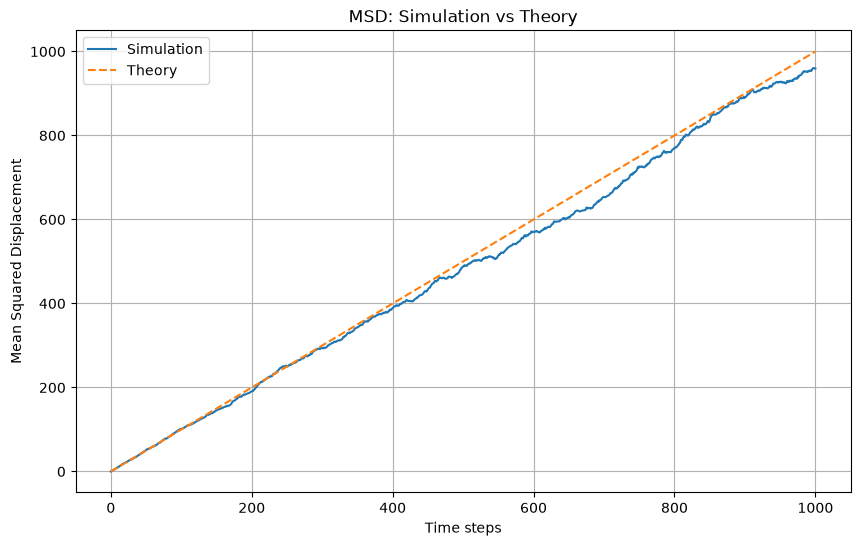

In [3]:
msd = np.mean(positions**2, axis=0)

time = np.arange(num_steps + 1)

theory = time

plt.figure(figsize=(10, 6))

plt.plot(time, msd, label="Simulation")
plt.plot(time, theory, "--", label="Theory")

plt.xlabel("Time steps")
plt.ylabel("Mean Squared Displacement")
plt.title("MSD: Simulation vs Theory")

plt.legend()
plt.grid(True)
plt.show()

## 4. Estimating the Diffusion Coefficient

The diffusion coefficient can be estimated from the slope of the MSD curve.

For one-dimensional diffusion:

$$MSD = 2Dt$$

Therefore:

$$D = \frac{\text{slope}}{2}$$

We use a linear fit to estimate the diffusion coefficient and compare it with the theoretical value of 0.5.

In [4]:
slope, intercept = np.polyfit(time, msd, 1)

D_estimated = slope / 2

print("Estimated diffusion coefficient:", D_estimated)
print("Theoretical diffusion coefficient:", 0.5)
print("Relative error (%):", abs(D_estimated - 0.5) / 0.5 * 100)

Estimated diffusion coefficient: 0.48336975604036697
Theoretical diffusion coefficient: 0.5
Relative error (%): 3.3260487919266057


## 5. Biased Random Walk

In a standard random walk, particles move left or right
with equal probability.

Now, we introduce a bias by changing the probabilities:

- Probability of moving right: 0.7
- Probability of moving left: 0.3

The goal is to investigate how directional bias affects
particle motion and diffusion.

We compare the biased random walk with the unbiased case.

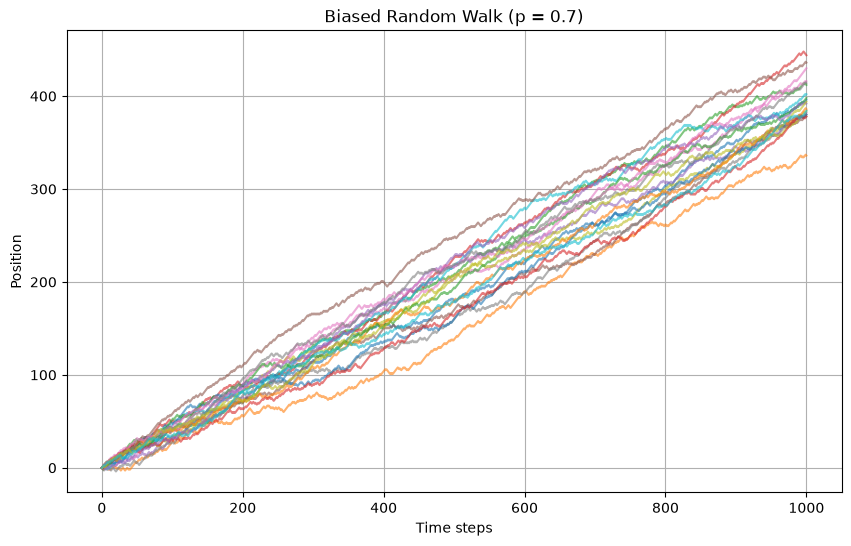

In [5]:
num_particles = 1000
num_steps = 1000

p = 0.7

biased_steps = np.random.choice([-1, 1], size=(num_particles, num_steps), p=[1-p, p])

biased_positions = np.cumsum(biased_steps, axis=1)

biased_positions = np.column_stack((np.zeros(num_particles), biased_positions))

plt.figure(figsize=(10, 6))

for i in range(20):
    plt.plot(biased_positions[i], alpha=0.6)

plt.xlabel("Time steps")
plt.ylabel("Position")
plt.title("Biased Random Walk (p = 0.7)")
plt.grid(True)
plt.show()

## 6. Comparing Biased and Unbiased Random Walks

We compare the average position of particles in two models:

1. Unbiased random walk (p = 0.5)
2. Biased random walk (p = 0.7)

For an unbiased random walk, the expected mean position is zero.
For a biased random walk, the expected mean position is:

$$\langle x(t)\rangle = (2p-1)t$$

We compare the numerical results with this theoretical prediction.

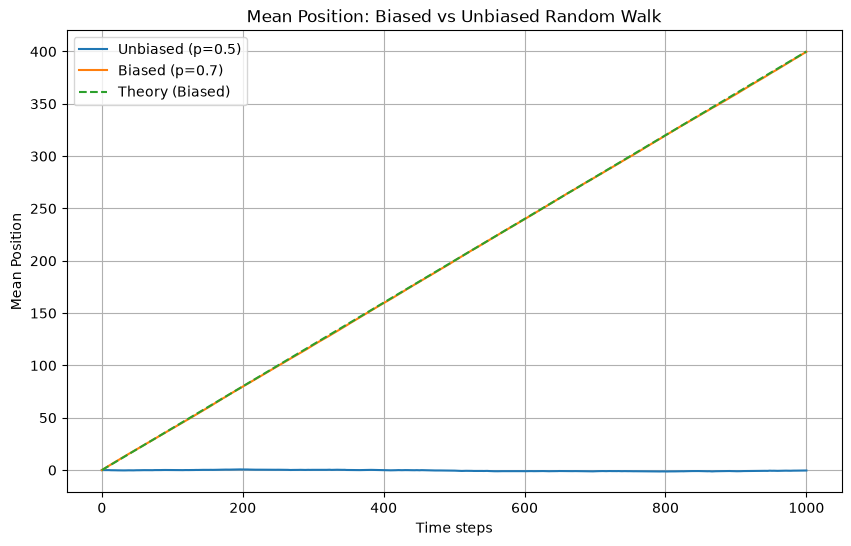

In [6]:
mean_unbiased = np.mean(positions, axis=0)
mean_biased = np.mean(biased_positions, axis=0)

time = np.arange(num_steps + 1)

theory_biased = (2*p - 1) * time

plt.figure(figsize=(10, 6))

plt.plot(time, mean_unbiased, label="Unbiased (p=0.5)")
plt.plot(time, mean_biased, label="Biased (p=0.7)")
plt.plot(time, theory_biased, "--", label="Theory (Biased)")

plt.xlabel("Time steps")
plt.ylabel("Mean Position")
plt.title("Mean Position: Biased vs Unbiased Random Walk")

plt.legend()
plt.grid(True)
plt.show()

## 7. Effect of Bias on Diffusion

We investigate how directional bias affects particle spreading.

For a biased random walk, the mean squared displacement
contains contributions from both drift and random fluctuations.

To measure spreading around the mean position, we calculate
the variance:

$$Var(x) = \langle(x-\langle x\rangle)^2\rangle$$

For independent steps of length 1:

$$Var(x(t)) = 4p(1-p)t$$

We compare the simulation with this theoretical prediction.

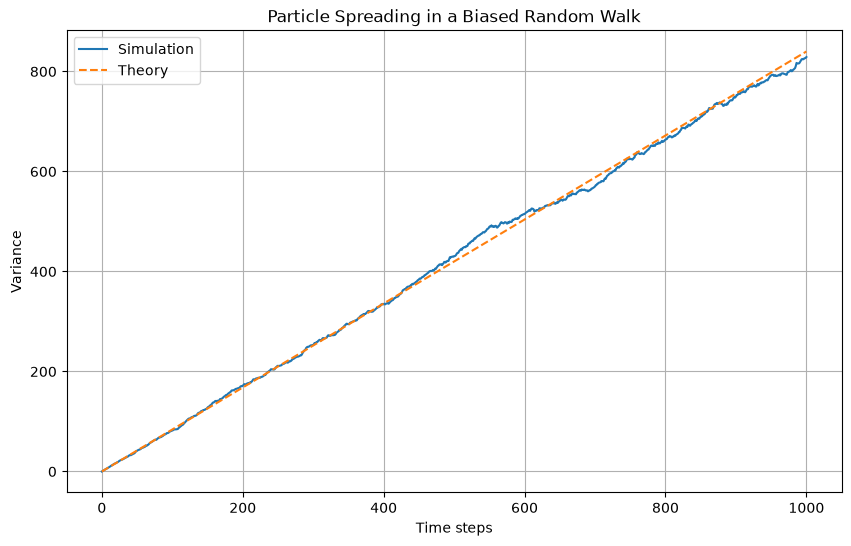

Estimated diffusion coefficient: 0.41433453281753
Theoretical diffusion coefficient: 0.42000000000000004


In [7]:
variance_biased = np.var(biased_positions, axis=0)

theory_variance = 4 * p * (1-p) * time

plt.figure(figsize=(10, 6))

plt.plot(time, variance_biased, label="Simulation")
plt.plot(time, theory_variance, "--", label="Theory")

plt.xlabel("Time steps")
plt.ylabel("Variance")
plt.title("Particle Spreading in a Biased Random Walk")

plt.legend()
plt.grid(True)
plt.show()

slope, intercept = np.polyfit(time, variance_biased, 1)

D_biased = slope / 2

print("Estimated diffusion coefficient:", D_biased)
print("Theoretical diffusion coefficient:", 2*p*(1-p))

## 8. Mean-Reverting Random Walk

Unlike a standard random walk, a mean-reverting process
tends to return toward an equilibrium position.

We model this behavior using a discrete
Ornstein-Uhlenbeck process:

$$x_{t+1} = x_t - \theta(x_t-\mu) + \sigma\epsilon_t$$

where:
- theta controls the strength of mean reversion.
- mu is the equilibrium position.
- sigma controls the random fluctuations.
- epsilon is Gaussian random noise.

Our goal is to compare mean-reverting motion
with a standard random walk and investigate
how the mean squared displacement changes over time.

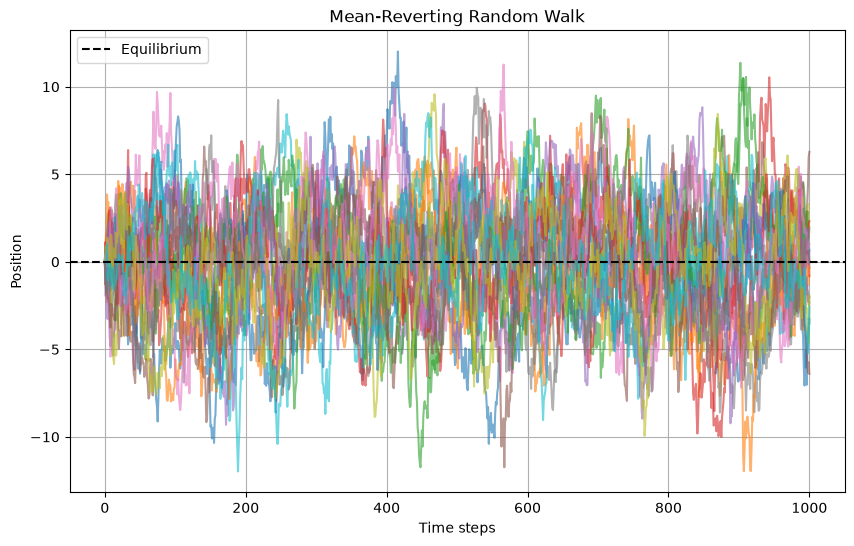

In [9]:
num_particles = 1000
num_steps = 1000

theta = 0.05
mu = 0
sigma = 1

rng = np.random.default_rng(42)

mr_positions = np.zeros((num_particles, num_steps + 1))

for t in range(num_steps):
    noise = rng.normal(0, 1, num_particles)

    mr_positions[:, t+1] = (mr_positions[:, t] - theta * (mr_positions[:, t] - mu) + sigma * noise)

plt.figure(figsize=(10, 6))

for i in range(20):
    plt.plot(mr_positions[i], alpha=0.6)

plt.axhline(mu, color="black", linestyle="--",
            label="Equilibrium")

plt.xlabel("Time steps")
plt.ylabel("Position")
plt.title("Mean-Reverting Random Walk")

plt.legend()
plt.grid(True)
plt.show()

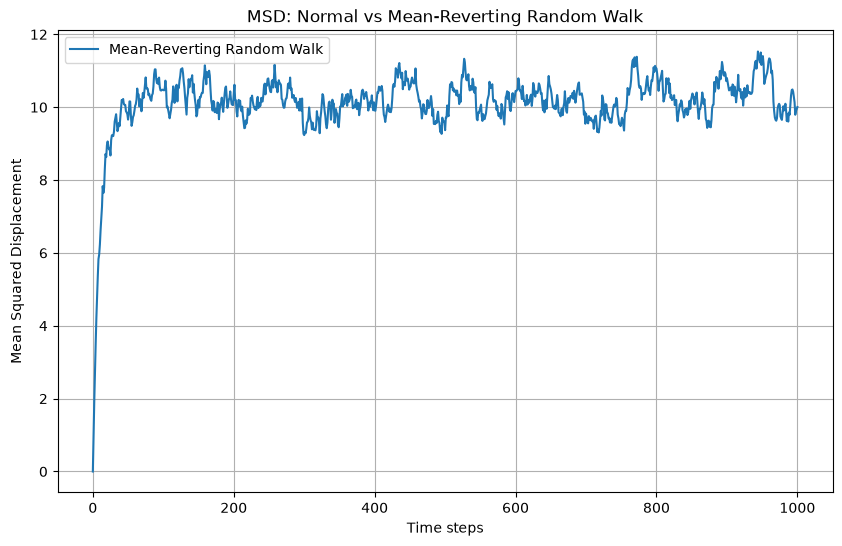

In [12]:
msd_normal = np.mean(positions**2, axis=0)
msd_mean_reverting = np.mean(mr_positions**2, axis=0)

time = np.arange(num_steps + 1)

plt.figure(figsize=(10, 6))

# plt.plot(time, msd_normal,
#          label="Standard Random Walk")

plt.plot(time, msd_mean_reverting,
         label="Mean-Reverting Random Walk")

plt.xlabel("Time steps")
plt.ylabel("Mean Squared Displacement")
plt.title("MSD: Normal vs Mean-Reverting Random Walk")

plt.legend()
plt.grid(True)
plt.show()

### Results

The graph shows a clear difference between standard and mean-reverting random waks. For the standard random walk, the mean squared displacement increases approximately linearly with time, indicating continuous particle spreading. In contrast, the mean-reverting process reaches a plateau at approximately MSD = 10. This demonstrates that mean reversion limits particle spreading by  introducing a restoring tendency toward the equilibrium position.

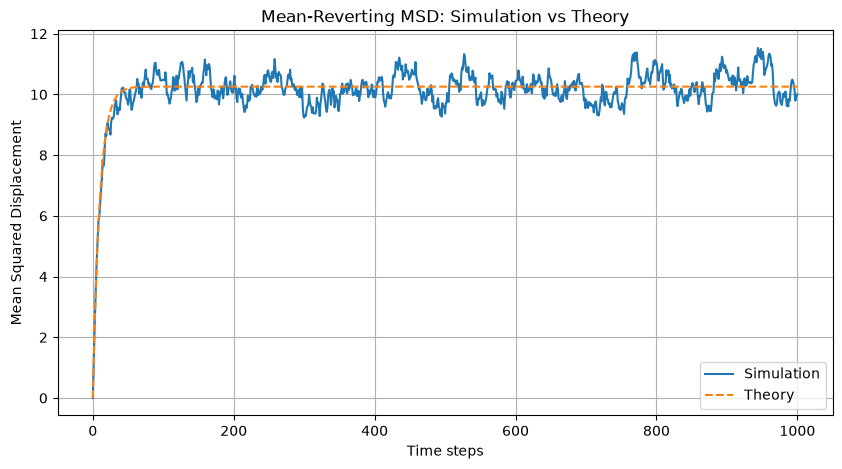

In [11]:
theory_mr = (sigma**2 * (1 - (1-theta)**(2*time)) / (2*theta - theta**2))

plt.figure(figsize=(10, 5))

plt.plot(time, msd_mean_reverting,
         label="Simulation")

plt.plot(time, theory_mr, "--",
         label="Theory")

plt.xlabel("Time steps")
plt.ylabel("Mean Squared Displacement")
plt.title("Mean-Reverting MSD: Simulation vs Theory")

plt.legend()
plt.grid(True)
plt.show()

## 10. Effect of Mean Reversion Strength

We investigate how the mean reversion parameter (theta) affects particle spreading.

We compare three values:

- Weak mean reversion: theta = 0.01
- Moderate mean reversion: theta = 0.05
- Strong mean reversion: theta = 0.2

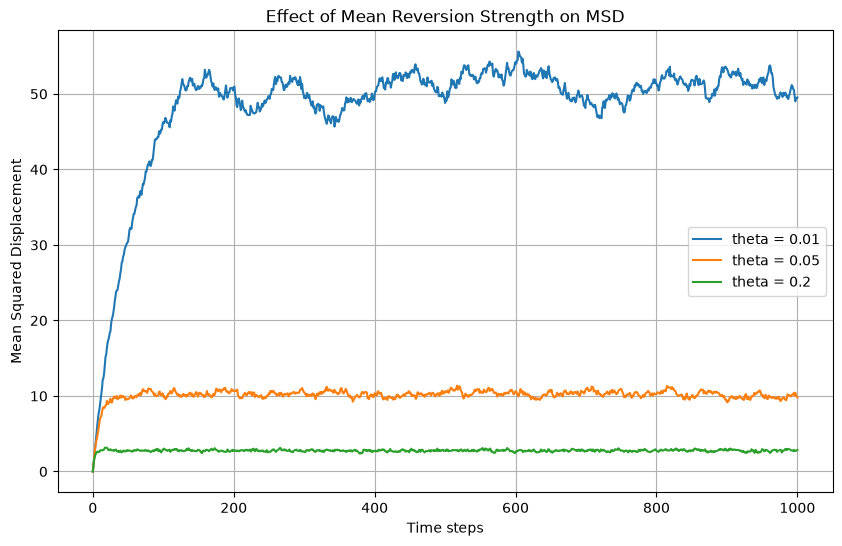

In [13]:
num_particles = 1000
num_steps = 1000

theta_values = [0.01, 0.05, 0.2]
sigma = 1

rng = np.random.default_rng(42)

plt.figure(figsize=(10, 6))

for theta in theta_values:

    x = np.zeros(num_particles)
    msd_values = [0]

    for t in range(num_steps):

        noise = rng.normal(0, 1, num_particles)

        x = x - theta * x + sigma * noise

        msd_values.append(np.mean(x**2))

    plt.plot(msd_values, label=f"theta = {theta}")

plt.xlabel("Time steps")
plt.ylabel("Mean Squared Displacement")
plt.title("Effect of Mean Reversion Strength on MSD")

plt.legend()
plt.grid(True)
plt.show()

### Results

The results show that the strength of mean reversion significantly affects particle spreading.For weak mean reversion (θ = 0.01), the MSD increases slowly and approaches a stationary value of approximately 50. For moderate mean reversion (θ = 0.05), the MSD stabilizes around 10, while for strong mean reversion (θ = 0.2), it quickly reaches approximately 2.8.

These results agree with the theoretical predictions of the discrete Ornstein-Uhlenbeck model.

Overall, stronger mean reversion leads to faster relaxation toward equilibrium and smaller fluctuations around the mean position.

## Conclusion

In this project, we investigated different types of random walks using Monte Carlo simulations.

For standard random walks, the mean squared displacement increased approximately linearly with time, consistent with normal diffusion. Introducing directional bias produced a systematic drift in particle motion and changed the effective diffusion coefficient. In contrast, mean-reverting random walks approached a stationary state, where the MSD stopped growing indefinitely. We also found that stronger mean reversion resulted in faster relaxation and smaller stationary fluctuations.

Overall, the simulations showed good agreement with theoretical predictions and demonstrated how different stochastic processes lead to different transport behaviors.